# Example calculation for density

Uses a very simplistic wrapper of the `lammps_logfile` module I made to better handle curing logs and then generalized it for other logs.
The wrapper will create a temporary file in the current working directory called `tmpfile` and then delete it on it's own.
It's a generalized way of reading thermo logs, but for more specific cases, more direct options are preferable (see `glass_transition.ipynb` for an example)

In [1]:
# temporary solution while I figure out packages
import sys
sys.path.insert(0,'../../src/')

from lammps_out import lammps_out_to_pd
import matplotlib.pyplot as plt

## Read LAMMPS thermo logs

In [4]:
df = lammps_out_to_pd(path="../../data/preparation/", # parent directory to the replicates
                      pattern="afd_annealing2.output", # log file
                      n_replicas=3, # number of replicates
                      skip_first=0, # skip first n timesteps
                      skip_last=0, # skip last n timesteps
                      timestep=1, # timestep in fs
                      timestep_offset=[0] # offset the timestep for each replica. If len is 1, then than value is applied to all replicates.
                      )
df

,Density,E_angle,E_bond,E_coul,E_dihed,E_pair,E_vdwl,KinEng,PotEng,Press,Temp,TotEng,c_rg,replica
Step,,,,,,,,,,,,,,
25.900000,1.117818,26598.567,21396.742,36765.614,-3393.1329,10184.176,212.753680,43031.740,55972.876,132.810550,302.60249,99004.616,89.910429,0
25.901000,1.120021,26355.265,21656.338,36757.951,-3421.9797,10206.708,239.699100,42632.098,55991.592,-196.435070,299.79218,98623.691,89.829409,0
25.902000,1.120800,26673.601,21617.205,36793.050,-3280.9351,10147.013,138.836530,42584.610,56351.923,-460.749820,299.45824,98936.534,89.812637,0
25.903000,1.122580,26464.149,21468.371,36761.719,-3158.1424,10231.063,256.063030,42570.303,56206.034,-442.303860,299.35763,98776.337,89.760849,0
25.904000,1.119287,26428.778,21621.986,36777.467,-3375.7693,10204.405,220.049770,42739.537,56056.646,-393.296420,300.54770,98796.183,89.868662,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26.002000,1.123350,26678.422,21699.527,36754.788,-3383.7674,10203.815,212.250080,42586.317,56404.989,-17.900826,299.47024,98991.306,123.762150,2
26.003000,1.124267,26574.359,21629.840,36772.045,-3256.2950,10129.379,113.829310,42575.268,56279.495,147.267870,299.39254,98854.763,123.722610,2
26.004000,1.121333,26570.594,21586.544,36801.414,-3297.9728,10143.656,98.624984,42746.327,56190.974,-532.555890,300.59544,98937.301,123.840580,2


## Plot Density vs Step

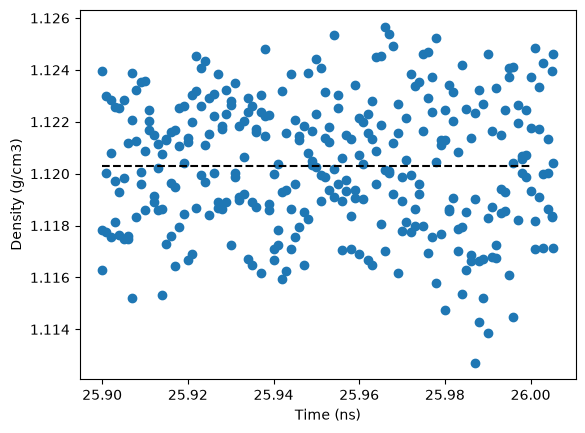

In [10]:
plt.plot(df['Density'], 'o')
plt.plot([25.9, 26], [df['Density'].mean()]*2, 'k--') # add the mean value
plt.xlabel('Time (ns)')
plt.ylabel('Density (g/cm3)')
plt.show()

## Read a single thermo log

In [12]:
df = lammps_out_to_pd(path="../../data/preparation/0/",
                      pattern="afd_annealing2.output",
                      n_replicas=1
                      )
df

,Density,E_angle,E_bond,E_coul,E_dihed,E_pair,E_vdwl,KinEng,PotEng,Press,Temp,TotEng,c_rg,replica
Step,,,,,,,,,,,,,,
25.950,1.120253,26620.793,21654.521,36743.703,-3520.9533,10308.650,354.06614,42689.488,56258.736,177.621300,300.19575,98948.224,89.843658,0
25.951,1.119962,26728.303,21408.979,36794.832,-3614.5016,10235.466,235.37727,42911.320,55943.178,-41.772363,301.75569,98854.498,89.837991,0
25.952,1.119856,26693.700,21494.733,36754.052,-3369.0801,10138.924,170.20313,42719.961,56165.293,-237.768980,300.41003,98885.253,89.830410,0
25.953,1.121222,26610.320,21533.797,36759.749,-3345.6237,10220.189,248.70938,42632.882,56244.052,-238.310630,299.79769,98876.934,89.812720,0
25.954,1.119088,26470.171,21461.134,36779.903,-3490.6443,10263.512,265.95082,42680.034,55889.314,-18.565987,300.12926,98569.348,89.880767,0
25.955,1.122534,26558.912,21793.147,36712.917,-3493.5293,10064.582,141.87442,42909.402,56125.982,500.062940,301.74220,99035.384,89.787613,0
25.956,1.117059,26675.450,21583.983,36821.469,-3486.9119,10577.213,542.10882,42751.654,56530.127,5.843719,300.63290,99281.780,89.925784,0
